# SecondLook | 05 Decision Letters with Claude

**Goal:** turn each applicant's risk score and SHAP reasons into a **clear, respectful, honest letter**, drafted by a large language model (Claude), checked automatically, and reviewed by a loan officer before it is sent.

**Why use an LLM here?** Templates ("Reason 1: EXT_SOURCE_MEAN") are accurate but unreadable, and hand-writing letters doesn't scale. An LLM can explain the *specific* reasons for *this* applicant in everyday language. The risk is that LLMs can **invent things**, so the whole design is about keeping Claude **grounded in the model's real reasons** and **checking** what it writes.

```
SHAP explanation ─► fact sheet ─► Claude Haiku 5.5 ─► structured letter (JSON) ─► guardrail checks ─┬─► passed ─► cache ─► loan officer reviews
 (Step 5)           (safe facts    (system prompt +     (letter + codes of the                       └─► failed ─► retry once with the problems listed
                     only)          structured output)   reasons it cited)
```

| Design choice | Why |
|---|---|
| **Fact sheet** instead of raw data | Claude only sees the decision, loan details and the top SHAP reasons. **Sensitive features are removed before the prompt**, so they can't leak into a letter |
| **Structured output** (Pydantic schema) | Claude returns the letter *and* the codes of the reasons it cited, so we can check them against SHAP |
| **Guardrail checks + one retry** | Rule-based checks catch common failures; if one fails, Claude gets the exact problem and one chance to fix it |
| **Claude Haiku 5.5, low effort** | Fast and very low-cost for short letters (as planned in the proposal) |
| **Cache** | Every letter is saved to disk. The app and the live demo never depend on the API or Wi-Fi for applicants already drafted |
| **Human in the loop** | Letters are **drafts for a loan officer**, never sent automatically |

**Bootcamp topics:** LLM fundamentals, prompt engineering, using the Claude API, integrating LLM responses into Python workflows, limitations and ethics of generative AI.

## 1. Setup

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import FIGURES_DIR, ID_COL
from secondlook.features import load_features
from secondlook import modeling as M
from secondlook.explain import Explainer
from secondlook import letters as L

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
print(f"Model: {L.MODEL}   effort: {L.EFFORT}   prompt version: {L.PROMPT_VERSION}")
print(f"Letter cache: {L.CACHE_PATH.relative_to(ROOT)}  ({len(json.loads(L.CACHE_PATH.read_text(encoding='utf-8'))) if L.CACHE_PATH.exists() else 0} letters cached)")

Model: claude-haiku-5-5   effort: low   prompt version: v5
Letter cache: data\processed\letter_cache.json  (60 letters cached)


## 2. Load the model, the explainer and the test applicants

We reuse the saved LightGBM model, the SHAP explainer from Step 5 and the same test set. Each applicant gets one of three **decisions**:

| Decision | Rule | Letter |
|---|---|---|
| `approve` | PD below the 0.17 cutoff | Confirms the approval and mentions strengths |
| `under_review` | PD within 5 points above the cutoff (SecondLook's borderline band) | Explains the main risk factors and strengths, says a loan officer will review it personally and may suggest adjusted terms |
| `decline` | PD further above the cutoff | Explains the main risk factors and strengths, what generally helps, and how to ask for a review |

In [2]:
model, meta = M.load_model()
df = load_features()
train, test = M.split(df)
test = test.set_index(ID_COL, drop=False)
X_test = M.prepare_X(test, meta["features"], meta["categorical"], meta["categories"])
pd_test = pd.Series(model.predict_proba(X_test)[:, 1], index=test.index)
explainer = Explainer(model)
cutoff = meta["cutoff"]

decisions = pd_test.map(lambda p: L.decision_for(p, cutoff))
decisions.value_counts().rename("test applicants").to_frame()

,test applicants
approve,54240
decline,4652
under_review,2611


**Interpretation:** most test applicants are approved. About 2,600 fall in the `under_review` band, the applicants SecondLook exists for, and about 4,650 are declined outright.

## 3. The fact sheet: what Claude is allowed to see

For each applicant we build a small **fact sheet** from their SHAP explanation. Two filters run **before** anything reaches Claude:

1. **Sensitive features are removed** (age, family status, children, family size). Claude can't mention what it never sees.
2. **Factors that mean nothing to an applicant are skipped**: building details, the day or hour they applied, region population density, and **occupation and employer type**. Employer types appear as codes like "Industry: type 4", and citing someone's *job* as a reason is easily read as unfair. These factors still appear in the loan officer's view in the app; the letter simply cites a *subset* of the true reasons, never anything else.

Here is the fact sheet for the borderline applicant from Step 5:

In [3]:
example_ids = {
    "Clear approval": 317152,
    "Borderline (under review)": 220127,
    "Clear decline": 178549,
}
fact_sheets = {}
for name, sid in example_ids.items():
    explanation = explainer.explain(X_test.loc[[sid]])
    fact_sheets[name] = L.build_letter_input(sid, explanation, test.loc[sid], cutoff)

print(fact_sheets["Borderline (under review)"].fact_sheet())

{
  "applicant_id": 220127,
  "decision": "under_review",
  "loan_amount": "284,400",
  "regular_payment": "18,644",
  "number_of_payments": "about 15 payments",
  "risk_factors": [
    {
      "code": "EXT_SOURCE_MEAN",
      "label": "Average external credit score",
      "value": "0.28"
    },
    {
      "code": "EXT_SOURCE_MIN",
      "label": "Lowest external credit score",
      "value": "0.03"
    },
    {
      "code": "INST_LATE_SHARE_LAST_YEAR",
      "label": "Share of payments late in the last year",
      "value": "23%"
    },
    {
      "code": "PREV_AVG_GRANTED_TO_APPLIED",
      "label": "Past loans granted vs amount requested",
      "value": "1.09x"
    }
  ],
  "strengths": [
    {
      "code": "BUR_DEBT_TO_CREDIT",
      "label": "Debt vs credit limit at other lenders",
      "value": "0%"
    },
    {
      "code": "EXT_SOURCE_3",
      "label": "External credit score 3",
      "value": "0.54"
    },
    {
      "code": "AMT_ANNUITY",
      "label": "Regular rep

**Interpretation:** the fact sheet holds just the decision, the loan details and four risk factors plus three strengths, each with a **code** (the real feature name), a **plain-English label** and the applicant's **value**. Compare with Step 5: this applicant's SHAP list also included *occupation* and *family status*. **Family status was removed** because it's sensitive, and occupation was skipped by the letter rules, so neither can appear in the letter.

## 4. The prompt (prompt engineering)

The **system prompt** sets Claude's role and rules. The key prompt-engineering choices:

- **Role and audience:** Claude drafts letters *for loan officers to review*, written *to applicants*.
- **Structure per decision type:** what an approval, under-review and decline letter must contain.
- **Grounding:** "use only the facts in the fact sheet"; never invent amounts, dates, policies or names.
- **No invented reasoning:** describe each factor only by its own value, with no comparisons to the current loan. *(Added after testing; see Section 8.)*
- **Fairness and clarity:** never mention personal characteristics; no technical jargon; never mention the internal tool name.
- **Traceability:** list the codes of every factor mentioned, so the letter can be checked against SHAP.

In [4]:
print(L.SYSTEM_PROMPT)

You draft decision letters for SecondLook, a tool used by loan officers at a consumer lender that serves people with little or no credit history. A loan officer reviews every draft before it is sent.

You receive a fact sheet about one application: the decision, the loan details, the main factors that RAISED the applicant's estimated risk, and the main factors that LOWERED it (their strengths). Each factor has a code, a plain-English label and the applicant's value.

Write a short letter to the applicant (120-220 words):
- Open with the decision in the first two sentences, clearly and kindly.
- For "decline" and "under_review" letters, explain the 2-3 most important risk factors in everyday words, and mention 1-2 genuine strengths.
- For "approve" letters, confirm the approval and mention 1-2 strengths; do not list risk factors.
- For "under_review", explain that the application is close to the approval threshold, so a loan officer will look at it personally, and that they may be conta

## 5. Draft letters for the three example applicants

`generate_letter()` sends the fact sheet to Claude using **structured outputs**: the SDK's `messages.parse()` with a Pydantic `Letter` schema (subject, body, reasons_cited, strengths_cited). The response is validated JSON, not free text we have to parse. Then the guardrail checks run.

Letters already in the cache are loaded instantly at no cost; new ones call the API once (about 3–7 seconds each).

In [5]:
example_letters = {}
for name, li in fact_sheets.items():
    r = L.generate_letter(li)
    example_letters[name] = r
    source = "(from cache)" if r["from_cache"] else f"(new: {r['seconds']}s, ${r['cost_usd']:.5f})"
    checks = "PASSED" if r["checks_passed"] else "FAILED " + str(r["issues"])
    print("=" * 100)
    print(f"{name.upper()}   applicant {r['applicant_id']}   decision: {r['decision']}   checks: {checks}   attempts: {r['attempts']}   {source}")
    print(f"Subject: {r['subject']}\n")
    print(r["body"])
    print(f"\nRisk factors cited: {r['reasons_cited']}\nStrengths cited:    {r['strengths_cited']}\n")

CLEAR APPROVAL   applicant 317152   decision: approve   checks: PASSED   attempts: 1   (new: 3.0s, $0.00033)
Subject: Your loan application has been approved

Dear Applicant,

We are pleased to tell you that your loan application has been approved. The approved loan amount is 1,546,020, to be repaid with regular payments of 40,914 over about 38 payments.

Your application shows several strengths. Your average external credit score is 0.69, which lenders read as a sign of a generally reliable credit history. You have also been in your current job for 18.2 years, and steady employment helps show that regular payments can be kept up.

Please review the loan terms carefully before you accept. If you have any questions about your repayment schedule or the next steps, please contact us and a member of our team will be happy to help.

Thank you for choosing us. We look forward to supporting you.

The Lending Team

Risk factors cited: []
Strengths cited:    ['EXT_SOURCE_MEAN', 'YEARS_EMPLOYED'

BORDERLINE (UNDER REVIEW)   applicant 220127   decision: under_review   checks: PASSED   attempts: 1   (new: 2.9s, $0.00040)
Subject: Update on your loan application

Thank you for applying with us. We are writing to let you know that your application is under review. This means a loan officer will look at your application personally before a final decision is made.

Your application is close to the level we need to approve a loan, so we want to take a closer look. Several factors in your file were considered. Your average external credit score is 0.28, and your lowest external credit score is 0.03. Lenders use these scores to understand how reliably past credit has been managed. In addition, 23% of your payments in the last year were late. On-time payments show a reliable repayment record, so this is an area that matters to us.

We also noted some genuine strengths. You currently have no debt compared with your credit limits at other lenders, which is a positive sign. Your external cr

CLEAR DECLINE   applicant 178549   decision: decline   checks: PASSED   attempts: 1   (new: 3.4s, $0.00042)
Subject: Your loan application decision

Thank you for applying with us. After careful review, we are unable to approve your loan application at this time.

Several factors in your application led to this decision. Your external credit scores were low, both on average and at their lowest point, which tells us your record with other lenders is still limited. Many of your past loan applications were also refused, and past loans you have held were generally for long repayment periods. These are the main factors that raised our concern.

We also want to recognise real strengths in your application. You have not been late on your instalment payments in the last year, and you have not been late in any month at other lenders. Your credit card balance is also at 0% of its limit. Lenders value this kind of steady, on-time repayment because it shows a reliable repayment record.

To strengt

**Interpretation:**
- **Each letter opens with the decision** and follows the structure for its type: the approval mentions strengths only; the under-review letter explains that a loan officer will look at it personally and may suggest adjusted terms; the decline explains the main reasons, names real strengths, says what generally helps and how to ask for a review.
- **Every factor mentioned is traceable.** The cited codes match the fact sheet, which comes straight from SHAP. For the borderline applicant, the letter names the same drivers Step 5 found (low external scores, 23% late payments in the last year) and the same strengths (no debt at other lenders).
- **Nothing sensitive and no jargon:** no age, family status, "model", "SHAP" or risk percentages, and no mention of the internal tool name.
- Each letter took one API call of roughly 1,700 input and 300–500 output tokens. At Haiku prices, that's **well under a tenth of a cent per letter**.
- **One subtle overstatement, found by reading carefully:** the decline letter says the low external scores mean the applicant's "record with other lenders is **still limited**". The fact sheet only says the scores are low, not that the record is limited; that part is Claude's own interpretation. It isn't harmful, but it isn't strictly grounded either, and **no keyword rule can catch it**. This is exactly why Phase 2 adds an independent faithfulness check (Section 9), and why a loan officer reviews every draft.

## 6. Guardrails: what the automatic checks catch

LLMs follow instructions *most* of the time, so we never trust the output blindly. `check_letter()` runs these rules on every letter:

| Check | Catches |
|---|---|
| Cited codes must come from the fact sheet | Reasons Claude invented or took from elsewhere |
| No sensitive codes or words (age, gender, marital status, children...) | Discriminatory content. "Age" is ignored only when the sentence is about a **car** (the age of the applicant's car is a real model factor) |
| No jargon (SHAP, log-odds, PD, algorithm...) | Technical language an applicant can't understand |
| No internal tool name ("SecondLook") | Leaking internal systems |
| No invented comparisons ("longer than your past loans", "similar to") | Made-up reasoning. Comparisons *to the price or income* are allowed, because those ratios are real factors |
| A decline or review letter must cite a reason and must not sound like an approval | Contradictory or empty letters |
| An approval letter must not list risk factors | Confusing approvals |
| Length 90–280 words | Letters that are too thin or too long |

These rules are covered by automated tests (`tests/test_letter_checks.py`, 16 tests). Here they are applied to some deliberately bad sentences:

In [6]:
li = fact_sheets["Clear decline"]
filler = "We have reviewed your application carefully. " * 15
probes = [
    "The loan amount is higher than the price of the goods it would cover.",
    "The loan term is longer than some of your past loans.",
    "Your car is 6 years old, which counts in your favour.",
    "As an older applicant, you may find repayment harder.",
    "Our SHAP analysis showed a high probability of default.",
    "A SecondLook review found several issues.",
    "Congratulations, your loan has been approved!",
]
rows = []
for text in probes:
    letter = L.Letter(subject="Your loan application decision", body=filler + text,
                      reasons_cited=["EXT_SOURCE_MEAN"], strengths_cited=[])
    issues = L.check_letter(letter, li)
    rows.append({"sentence added to a letter": text, "result": "flagged" if issues else "passes", "issue": "; ".join(issues)})
pd.DataFrame(rows)

,sentence added to a letter,result,issue
0,The loan amount is higher than the price of the goods it would cover.,passes,
1,The loan term is longer than some of your past loans.,flagged,possible invented comparison: 'longer than some of your past l...' (describe factors only by their own value)
2,"Your car is 6 years old, which counts in your favour.",passes,
3,"As an older applicant, you may find repayment harder.",flagged,mentions a personal characteristic: 'older'
4,Our SHAP analysis showed a high probability of default.,flagged,uses technical jargon: 'SHAP'
5,A SecondLook review found several issues.,flagged,mentions the internal tool name SecondLook
6,"Congratulations, your loan has been approved!",flagged,tone says approved but the decision is not an approval


**Interpretation:** the checks flag the invented comparison, the reference to the applicant's age, the jargon, the internal tool name and the approval wording in a decline letter. They correctly **let through** the two legitimate sentences: the loan really is higher than the goods price (a real ratio factor), and the car's age is a real factor, not a personal characteristic.

## 7. Drafting letters for the demo set

The app needs letters ready for its demo applicants. We select a reproducible set of **30 test applicants: 10 approvals, 10 under review and 10 declines**, and draft a letter for each. They are cached, so re-running this cell (or the app) costs nothing.

In [7]:
demo_ids = L.select_demo_applicants(pd_test, cutoff, n_each=10)
results = []
for sid in demo_ids:
    li = L.build_letter_input(sid, explainer.explain(X_test.loc[[sid]]), test.loc[sid], cutoff)
    results.append(L.generate_letter(li))
batch = pd.DataFrame(results)
batch["words"] = batch["body"].str.split().str.len()

summary = batch.groupby("decision").agg(
    letters=("applicant_id", "size"),
    passed_checks=("checks_passed", "mean"),
    needed_retry=("attempts", lambda a: (a > 1).sum()),
    avg_words=("words", "mean"),
    avg_seconds=("seconds", "mean"),
    total_cost_usd=("cost_usd", "sum"),
).reindex(["approve", "under_review", "decline"])

(ROOT / "data" / "processed" / "demo_ids.json").write_text(json.dumps(demo_ids))
print(f"Letters: {len(batch)}   passed checks: {batch['checks_passed'].mean():.0%}   "
      f"needed a retry: {(batch['attempts'] > 1).sum()}   total cost: ${batch['cost_usd'].sum():.4f}   "
      f"cost per letter: ${batch['cost_usd'].mean():.5f}")
summary.style.format({"passed_checks": "{:.0%}", "avg_words": "{:.0f}", "avg_seconds": "{:.1f}", "total_cost_usd": "${:.4f}"})

Letters: 30   passed checks: 100%   needed a retry: 4   total cost: $0.0193   cost per letter: $0.00064


,letters,passed_checks,needed_retry,avg_words,avg_seconds,total_cost_usd
decision,,,,,,
approve,10,100%,1,139,4.2,$0.0054
under_review,10,100%,3,198,6.5,$0.0087
decline,10,100%,0,187,4.4,$0.0053


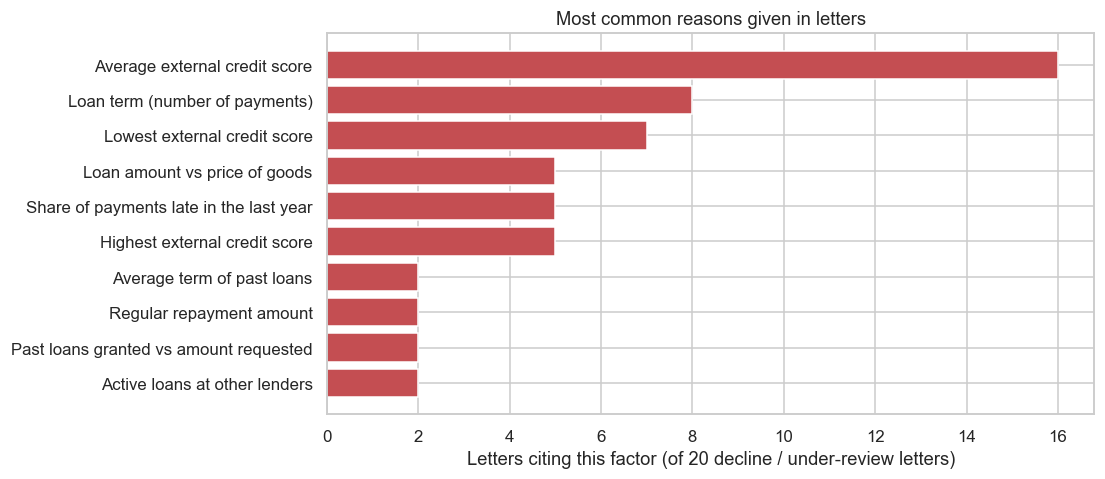

In [8]:
# Which risk factors do the letters cite most often?
cited = pd.Series([c for codes in batch["reasons_cited"] for c in codes])
from secondlook.explain import label_of
counts = cited.map(label_of).value_counts().head(10)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(counts.index[::-1], counts.values[::-1], color="#C44E52")
ax.set(xlabel="Letters citing this factor (of 20 decline / under-review letters)", title="Most common reasons given in letters")
fig.savefig(FIGURES_DIR / "24_letter_reasons.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- **All 30 letters passed every check.** A few needed their **one automatic retry**: the first draft broke a rule, Claude was told exactly what to fix, and the second draft passed. The retry loop does its job.
- Approval letters are shorter (around 140 words) than decline and under-review letters (around 190–200 words), as intended: declines explain more.
- **Cost:** about **2 cents for all 30 letters**, well under a tenth of a cent each, at a few seconds per letter. Drafting letters for every one of the ~7,300 declined test applicants would cost only about **$5**.
- The reasons cited most often mirror Step 5's borderline analysis: **external credit scores** dominate, followed by **loan term**, then **loan amount vs goods price** and **recent late payments**.

The demo applicant IDs are saved to `data/processed/demo_ids.json` for the Streamlit app.

## 8. What testing taught us (development log)

We didn't get here on the first try. Reviewing drafts by hand and measuring check results led to five prompt versions:

| Version | Problem found by reviewing letters | Fix |
|---|---|---|
| v1 | Claude **invented comparisons**, e.g. "the amount you requested before is similar to what you are asking for now", when the numbers (409,867 vs 1,546,020) were not similar at all | Prompt rule: describe each factor only by its own value; no comparisons |
| v2 | A subject line said "Your **SecondLook** application"; values like "37.8 payments" read awkwardly; factors like "average amount requested before" meant nothing to an applicant | Never mention the internal tool name; round values; skip unclear factors |
| v3 | Letters could cite occupation or employer codes ("Industry: type 4") | Keep job and employer out of letters (officers still see them) |
| v4 | Batch of 30: 26 passed. **All 4 failures were false alarms** (the age of the applicant's *car*, and the phrase "take a *second look*"), while **one real invented comparison slipped through** ("longer than some of your past loans") | Smarter checks: car age allowed, tool name matched only as a name, new comparison check that still allows true ratio statements |
| v5 | All 30 pass; the earlier invented comparison is now caught | Current version |

**Lesson:** an LLM feature isn't finished when the output *looks* good. It needs to be tested against the facts, and the tests themselves need testing, in both directions (false alarms and missed problems).

## 9. Limitations and Phase 2

- **Rule-based checks can't understand meaning.** They catch known patterns, but a letter could still describe a factor misleadingly in words no rule anticipates. **Phase 2 adds an independent faithfulness check:** a second Claude call extracts each claim from the letter and compares it with the SHAP fact sheet, and **VADER, TextBlob and Claude Haiku tone scores** flag letters that read as harsh.
- **The path to approval** (Phase 2) will add concrete, re-scored suggestions such as *"a loan of X over Y payments would likely be approved"* to under-review letters.
- **Human review stays essential.** A loan officer approves every draft. SecondLook assists the decision; it doesn't make it.
- **Applicant-facing numbers:** letters sometimes quote raw values (e.g. an external score of 0.28). That's factual, but a production lender would decide which values applicants should see.

## 10. Summary

| Question | Answer |
|---|---|
| How are letters produced? | SHAP reasons → safe fact sheet → Claude Haiku 5.5 with structured output → guardrail checks (one retry) → cache → officer review |
| Are they grounded in the model? | Yes: every cited factor is a code from the SHAP fact sheet, and the checks reject anything else |
| Are they fair? | Sensitive features never reach the prompt, and the checks block personal characteristics |
| Do they pass the checks? | 30 of 30 demo letters, a few after one automatic retry |
| Cost and speed | About $0.0006 per letter and a few seconds each; the demo set cost about 2 cents |
| Reliability for the demo | All demo letters are cached, so no live API call is needed during the presentation |

**Reusable code:** `src/secondlook/letters.py` (`build_letter_input`, `generate_letter`, `check_letter`), plus tests in `tests/test_letter_checks.py`.

**Next: Step 7, the Streamlit MVP**: an applicant scoring page with the risk score, SHAP reasons and the drafted letter, plus a portfolio dashboard and a model card.